# Physics-Only Model — TEMA Type A Shell & Tube

**Approach:** Pure physics (no ML).

**Fixed geometry:** TEMA Type A shell, 2-pass tubes (triangular pitch)
- 160 tubes, L = 6 m, d_o = 0.020 m, pitch = 0.050 m

**Inputs:**
- mass flow of air (`m_dot_air`, kg/s)
- mass flow of water (`m_dot_water`, kg/s)
- air inlet temperature (`T_air_in`, °C)
- water inlet temperature (`T_water_in`, °C)

**Outputs:**
- Overall U (physics film coefficients)
- Air outlet temperature
- Water outlet temperature

**Udata (for comparison):** overall U from dataset temperatures via **LMTD**:
`Udata = Qavg / (A · LMTD)`

Uses temperature-dependent fluid properties + iterative E-NTU (1 shell / 2 tube passes).


## 1. Physics Code

In [1]:
import math

# FLUID PROPERTY FUNCTIONS
# These calculate density, viscosity, cp, conductivity, and Pr
# from temperature. We do NOT assume constant properties.


def get_water_properties(T_c):
    
    """Calculate water properties at a given temperature (°C).
    Returns: density, viscosity, specific heat, conductivity, Prandtl number."""
    
    # Keep temperature inside liquid-water range (1 to 100 °C)
    T = max(1.0, min(T_c, 100.0))

    # Density of water (kg/m³) — changes with temperature
    rho = 1000.0 - 0.0178 * abs(T - 4.0)**1.7

    # Dynamic viscosity (Pa·s) — water becomes less viscous when hotter
    mu = 0.00179 * math.exp(-0.0247 * T)

    # Specific heat capacity (J/kg·K)
    cp = 4182.0 - 0.25 * T

    # Thermal conductivity (W/m·K)
    k = 0.57 + 0.0017 * T

    # Prandtl number = (momentum diffusivity) / (thermal diffusivity)
    Pr = (cp * mu) / k

    return rho, mu, cp, k, Pr


def get_air_properties(T_c, P_atm=101325.0):
    
    """Calculate air properties at a given temperature (°C).
    Returns: density, viscosity, specific heat, conductivity, Prandtl number."""
    
    # Convert Celsius to Kelvin (needed for ideal gas law)
    T_k = T_c + 273.15

    # Ideal gas constant for air (J/kg·K)
    R_spec = 287.05

    # Air density from ideal gas law: rho = P / (R * T)
    rho = P_atm / (R_spec * T_k)

    # Sutherland's law — viscosity of air vs temperature
    mu_ref = 1.716e-5   # reference viscosity at T_ref
    T_ref = 273.15      # reference temperature (K)
    S = 110.4           # Sutherland constant
    mu = mu_ref * ((T_k / T_ref)**1.5) * ((T_ref + S) / (T_k + S))

    # Specific heat of air (J/kg·K)
    cp = 1005.0 + 0.05 * T_c

    # Thermal conductivity of air (W/m·K)
    k = 0.0241 + 7.5e-5 * T_c

    # Prandtl number for air
    Pr = (cp * mu) / k

    return rho, mu, cp, k, Pr


# MAIN PHYSICS MODEL
# Purpose:
#   Inputs  -> air/water mass flow + inlet temperatures
#   Outputs -> Overall U, air outlet temp, water outlet temp
# Method:
#   1) Calculate outlet temperatures
#   2) Get fluid properties at average temperatures
#   3) Calculate film coefficients (hi, ho) and overall U
#   4) Use E-NTU method to get new outlet temperatures
#   5) Repeat until outlets stop changing (convergence)


def rate_shell_and_tube_1_2(
    
    # ----- Operating inputs (what the user / process gives) -----
    T_air_in=150.0,      # Hot air inlet temperature (°C)
    m_dot_air=1.8,       # Air mass flow rate (kg/s)
    T_water_in=25.0,     # Cooling water inlet temperature (°C)
    m_dot_water=3.5,     # Water mass flow rate (kg/s)

    # ----- Fixed exchanger geometry (TEMA shell, 2 tube passes) -----
    N_tubes=160,             # Number of tubes
    N_passes=2,              # Tube-side passes
    L=6.0,                   # Tube length (m)
    d_o=0.020,             # Tube outer diameter (m)
    wall_thickness=0.002,  # Tube wall thickness (m)
    pitch=0.050,             # Tube pitch — triangular layout (m)
    D_s=0.387,               # Shell inner diameter (m)
    B=0.8,                  # Baffle spacing (m)
    k_wall=45.0,             # Tube wall thermal conductivity (W/m·K)

    # ----- Fouling resistances (dirt layer resistance) -----
    R_fi=0.00015,            # Fouling inside tubes (water side)
    R_fo=0.00035,            # Fouling outside tubes (air side)

    # ----- Iteration / solver settings -----
    tol=1e-5,                # Stop when outlet temps change less than this
    max_iter=100,            # Maximum number of iterations allowed
    omega=0.5                # Relaxation factor (0.5 = mix old and new guess)
):
    
    # STEP A: Geometry values derived from fixed dimensions

    # Inner tube diameter from outer diameter and wall thickness
    d_i = d_o - 2 * wall_thickness

    # Total outer heat transfer area of all tubes (m²)
    A_o_total = N_tubes * (math.pi * d_o * L)

    # Tubes in one pass (flow splits among these tubes)
    N_tubes_per_pass = N_tubes / N_passes

    # Cross-section area available for water flow inside tubes (m²)
    A_flow_tube = N_tubes_per_pass * (math.pi * d_i**2 / 4)

    # Clearance between tubes (used in Kern shell-side method)
    C_prime = pitch - d_o

    # Shell-side cross-flow area for air (m²)
    A_s = (D_s * C_prime * B) / pitch

    # Equivalent diameter for shell-side correlations (triangular pitch, Kern)
    D_e = 4 * (0.86 * pitch**2 - (math.pi * d_o**2 / 4)) / (math.pi * d_o)

    # Number of baffles along the shell
    N_b = max(1, math.floor(L / B) - 1)

    # STEP B: Initial guesses for outlet temperatures
    # We need guesses because properties depend on temperature,
    # and temperature depends on heat transfer (circular link).
    
    T_h_out = T_air_in - 30.0     # first guess for air outlet
    T_c_out = T_water_in + 10.0   # first guess for water outlet

    # STEP C: Iteration loop until outlet temperatures converge
    for iteration in range(1, max_iter + 1):

        # 1) Average temperatures for property evaluation
        T_h_avg = 0.5 * (T_air_in + T_h_out)      # air mean temp
        T_c_avg = 0.5 * (T_water_in + T_c_out)    # water mean temp

        # 2) Fluid properties at those average temperatures
        rho_w, mu_w, cp_w, k_w, Pr_w = get_water_properties(T_c_avg)
        rho_a, mu_a, cp_a, k_a, Pr_a = get_air_properties(T_h_avg)

        # 3) Tube-side heat transfer coefficient (water inside tubes)
        #    Velocity -> Reynolds -> Nusselt (Dittus–Boelter) -> hi
        u_i = m_dot_water / (rho_w * A_flow_tube)     # water velocity (m/s)
        Re_i = (rho_w * u_i * d_i) / mu_w             # tube Reynolds number
        Nu_i = 0.023 * (Re_i**0.8) * (Pr_w**0.4)      # Nusselt number
        h_i = (Nu_i * k_w) / d_i                      # film coefficient (W/m²·K)

        # 4) Shell-side heat transfer coefficient (air outside tubes)
        #    Using Kern's method
        G_s = m_dot_air / A_s                         # mass velocity (kg/m²·s)
        u_s = G_s / rho_a                             # air velocity (m/s)
        Re_s = (G_s * D_e) / mu_a                     # shell Reynolds number
        Nu_o = 0.36 * (Re_s**0.55) * (Pr_a**(1.0 / 3.0))
        h_o = (Nu_o * k_a) / D_e                      # film coefficient (W/m²·K)

        # 5) Overall heat transfer coefficient U based on outer area
        #    Total resistance = convection + fouling + wall conduction
        R_conv_i = (1.0 / h_i) * (d_o / d_i)          # inside convection (referred to outer area)
        R_foul_i = R_fi * (d_o / d_i)                 # inside fouling
        R_cond = (d_o * math.log(d_o / d_i)) / (2.0 * k_wall)  # metal wall
        R_foul_o = R_fo                               # outside fouling
        R_conv_o = 1.0 / h_o                          # outside convection

        # Overall U = 1 / total thermal resistance
        U_o = 1.0 / (R_conv_i + R_foul_i + R_cond + R_foul_o + R_conv_o)

        # 6) E-NTU method to find heat duty and outlet temperatures
        #    (for 1 shell pass / 2 tube passes exchanger)
        C_h = m_dot_air * cp_a                        # air heat capacity rate (W/K)
        C_c = m_dot_water * cp_w                      # water heat capacity rate (W/K)
        C_min = min(C_h, C_c)
        C_max = max(C_h, C_c)
        C_r = C_min / C_max                           # capacity ratio

        # Number of Transfer Units
        NTU = (U_o * A_o_total) / C_min

        # Effectiveness (epsilon) for 1-2 TEMA shell-and-tube
        E = math.sqrt(1.0 + C_r**2)
        exp_term = math.exp(-NTU * E)
        epsilon = 2.0 / (1.0 + C_r + E * ((1.0 + exp_term) / (1.0 - exp_term)))

        # Maximum possible heat transfer and actual heat transfer
        Q_max = C_min * (T_air_in - T_water_in)
        Q = epsilon * Q_max                           # actual duty (W)

        # New outlet temperatures from energy balance
        T_h_out_new = T_air_in - (Q / C_h)            # air cools down
        T_c_out_new = T_water_in + (Q / C_c)          # water heats up

        # 7) Check if solution has converged
        diff = max(abs(T_h_out_new - T_h_out), abs(T_c_out_new - T_c_out))
        if diff < tol:
            # Outlet temperatures are stable enough — stop iterating
            break

        # Soft update (damping) to keep the iteration stable
        T_h_out = omega * T_h_out_new + (1.0 - omega) * T_h_out
        T_c_out = omega * T_c_out_new + (1.0 - omega) * T_c_out

    
    # STEP D: Pressure drop estimates at the final converged state
    # (extra results; main targets are still U, Taout, Twout)

    # Tube-side (water) friction factor and pressure drop
    f_i = 0.3164 * (Re_i**-0.25) if Re_i > 4000 else 64.0 / max(Re_i, 1.0)
    dp_tube_friction = f_i * (L / d_i) * (0.5 * rho_w * u_i**2)
    dp_tube_bends = 2.5 * (0.5 * rho_w * u_i**2)
    dP_tube = N_passes * (dp_tube_friction + dp_tube_bends)

    # Shell-side (air) pressure drop
    f_s = 1.44 * (Re_s**-0.15) if Re_s > 500 else 0.5
    dP_shell = f_s * (D_s / D_e) * (N_b + 1) * (0.5 * rho_a * u_s**2)

   
    # STEP E: Return all important results
    # Main outputs for the digital twin:
    #   - Overall_U
    #   - Air_Outlet_Temp
    #   - Water_Outlet_Temp
   
    return {
        "Iterations_to_Converge": iteration,
        "Air_Inlet_Temp (°C)": round(T_air_in, 2),
        "Air_Outlet_Temp (°C)": round(T_h_out, 2),
        "Water_Inlet_Temp (°C)": round(T_water_in, 2),
        "Water_Outlet_Temp (°C)": round(T_c_out, 2),
        "Calculated_Duty (kW)": round(Q / 1000.0, 2),
        "Overall_U (W/m²·K)": round(U_o, 2),
        "h_inside_water (W/m²·K)": round(h_i, 2),
        "h_outside_air (W/m²·K)": round(h_o, 2),
        "Exchanger_Effectiveness (ε)": round(epsilon, 4),
        "NTU": round(NTU, 3),
        "dP_Shell_Air (kPa)": round(dP_shell / 1000.0, 3),
        "dP_Tube_Water (kPa)": round(dP_tube / 1000.0, 3),
        "Re_Shell (Air)": round(Re_s, 0),
        "Re_Tube (Water)": round(Re_i, 0)
    }




# ----- Module-level TEMA Type A constants (same as function defaults) -----
N_TUBES = 160
L_TUBE = 6.0
D_O = 0.020
WALL_THICKNESS = 0.002
PITCH = 0.050
D_S = 0.387
B_BAFFLE = 0.8
D_I = D_O - 2.0 * WALL_THICKNESS
A_O_TOTAL = N_TUBES * (math.pi * D_O * L_TUBE)
A_o_total = A_O_TOTAL
D_E = 4.0 * (0.86 * PITCH ** 2 - (math.pi * D_O ** 2 / 4.0)) / (math.pi * D_O)
print(f"TEMA Type A geometry: A_o = {A_o_total:.4f} m2 | De = {D_E:.5f} m (triangular)")

# DEMO RUN
# Run the physics model once with default input values
# and print all results.

rated_results = rate_shell_and_tube_1_2()
for k, v in rated_results.items():
    print(f"{k}: {v}")


TEMA Type A geometry: A_o = 60.3186 m2 | De = 0.11687 m (triangular)
Iterations_to_Converge: 23
Air_Inlet_Temp (°C): 150.0
Air_Outlet_Temp (°C): 70.71
Water_Inlet_Temp (°C): 25.0
Water_Outlet_Temp (°C): 34.87
Calculated_Duty (kW): 144.22
Overall_U (W/m²·K): 32.62
h_inside_water (W/m²·K): 1387.97
h_outside_air (W/m²·K): 34.28
Exchanger_Effectiveness (ε): 0.6343
NTU: 1.082
dP_Shell_Air (kPa): 0.335
dP_Tube_Water (kPa): 0.825
Re_Shell (Air): 51084.0
Re_Tube (Water): 4074.0


## 2. Load dataset, compute Udata (LMTD), evaluate physics

- Load `data.csv`
- Compute **Udata** from dataset temperatures using LMTD and TEMA area
- Run physics rating on every row
- Compare physics **U** to **Udata** (not CSV `U_actual`); outlets to dataset temps


In [2]:
# LOAD AND CLEAN THE HEAT EXCHANGER DATASET
# Then compute Udata from LMTD using TEMA area A_o_total.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

DATA_DIR = Path(r"c:\Users\krish\JBS Tech\Heat exchanger Digital Twin\Serial Model")
data_path = DATA_DIR / "data.csv"
if not data_path.exists():
    data_path = Path("data.csv")
if not data_path.exists():
    raise FileNotFoundError("data.csv not found")

df_raw = pd.read_csv(data_path, header=1)
if "State" in df_raw.columns:
    df_raw = df_raw[df_raw["State"].astype(str).str.startswith("Case")].copy()

cols = {
    "Hot Air flow in Shell": "m_air_kgh",
    "Cooling water flow in Tubes": "m_water_kgh",
    "1 - Temperature": "T_air_in",
    "3 - Temperature": "T_water_in",
    "2 - Temperature": "T_air_out",
    "4 - Temperature": "T_water_out",
    "E-100 - Overall U": "U_actual",
}

df = df_raw[list(cols.keys())].rename(columns=cols).copy()
for c in df.columns:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df = df.dropna().reset_index(drop=True)

df["m_air"] = df["m_air_kgh"] / 3600.0
df["m_water"] = df["m_water_kgh"] / 3600.0

print("Loaded:", data_path.resolve())
print("Clean shape:", df.shape)
print(df.head())


# ----- Udata from LMTD (same formulas as Serial / Parallel / PINN) -----
def lmtd_counterflow(T_air_in, T_water_in, T_air_out, T_water_out, eps=1e-8):
    """LMTD = (dT1 - dT2) / ln(dT1/dT2)."""
    dT1 = T_air_in - T_water_out
    dT2 = T_air_out - T_water_in
    if dT1 <= eps or dT2 <= eps:
        return float("nan")
    if abs(dT1 - dT2) < eps:
        return 0.5 * (dT1 + dT2)
    return (dT1 - dT2) / math.log(dT1 / dT2)


def udata_from_lmtd(m_air, m_water, T_air_in, T_water_in, T_air_out, T_water_out, A=None):
    """Overall U from dataset temperatures via LMTD."""
    if A is None:
        A = A_o_total
    LMTD = lmtd_counterflow(T_air_in, T_water_in, T_air_out, T_water_out)
    if not math.isfinite(LMTD) or LMTD <= 0.0 or A <= 0.0:
        return float("nan")
    Thavg = 0.5 * (T_air_out + T_air_in)
    Tcavg = 0.5 * (T_water_in + T_water_out)
    _, _, Cp_h, _, _ = get_air_properties(Thavg)
    _, _, Cp_c, _, _ = get_water_properties(Tcavg)
    Qh = m_air * Cp_h * (T_air_in - T_air_out)
    Qc = m_water * Cp_c * (T_water_out - T_water_in)
    Qavg = 0.5 * (Qh + Qc)
    return Qavg / (A * LMTD)


df["Udata"] = [
    udata_from_lmtd(
        float(r["m_air"]), float(r["m_water"]),
        float(r["T_air_in"]), float(r["T_water_in"]),
        float(r["T_air_out"]), float(r["T_water_out"]),
    )
    for _, r in df.iterrows()
]
df = df.dropna(subset=["Udata"]).reset_index(drop=True)

print("Udata calculated for", len(df), "rows | A =", round(A_o_total, 4), "m2")
print(df[["T_air_in", "T_air_out", "T_water_in", "T_water_out", "U_actual", "Udata"]].head(8).to_string(index=False))
print("\nUdata stats:")
print(df["Udata"].describe().round(3))


Loaded: C:\Users\krish\JBS Tech\Heat exchanger Digital Twin\Serial Model\data.csv
Clean shape: (7526, 9)
   m_air_kgh  m_water_kgh  T_air_in  T_water_in  T_air_out  T_water_out  \
0    10000.0      10000.0     100.0        25.0      69.25        32.12   
1    10000.0      10000.0     150.0        25.0      98.14        37.10   
2    10000.0      10000.0     200.0        25.0     126.70        42.24   
3    10000.0      10000.0     250.0        25.0     155.00        47.50   
4    10000.0      10000.0     300.0        25.0     183.10        52.89   

   U_actual     m_air   m_water  
0     26.67  2.777778  2.777778  
1     27.33  2.777778  2.777778  
2     27.94  2.777778  2.777778  
3     28.49  2.777778  2.777778  
4     28.98  2.777778  2.777778  
Udata calculated for 7526 rows | A = 60.3186 m2
 T_air_in  T_air_out  T_water_in  T_water_out  U_actual     Udata
    100.0      69.25        25.0        32.12     26.67 25.333225
    150.0      98.14        25.0        37.10     27.33 25.8

In [3]:
# RUN PHYSICS MODEL ON EVERY DATA ROW
# Goal:
#   For each case, use the 4 inputs to predict:
#   U, air outlet temperature, and water outlet temperature.
#   Then store results so we can compare with Dataset later.

def physics_predict_row(m_air, m_water, T_air_in, T_water_in):
    
    """Run the full physics model for one operating point.
    Inputs : mass flows (kg/s) and inlet temperatures (°C)
    Returns: U, Taout, Twout, and number of iterations used"""
    
    # Call the main shell-and-tube function
    res = rate_shell_and_tube_1_2(
        T_air_in=float(T_air_in),
        m_dot_air=float(m_air),
        T_water_in=float(T_water_in),
        m_dot_water=float(m_water),)

    # Keep only the main outputs we need for comparison
    return (
        res["Overall_U (W/m²·K)"],
        res["Air_Outlet_Temp (°C)"],
        res["Water_Outlet_Temp (°C)"],
        res["Iterations_to_Converge"],)

# Empty lists to collect predictions for all rows
U_list, Ta_list, Tw_list, it_list = [], [], [], []

# Loop through every cleaned data row
for i, row in df.iterrows():
    # Predict U, Taout, Twout from this row's 4 inputs
    U_p, Ta_p, Tw_p, n_it = physics_predict_row(
        row["m_air"], row["m_water"], row["T_air_in"], row["T_water_in"])

    # Save results for this row
    U_list.append(U_p)
    Ta_list.append(Ta_p)
    Tw_list.append(Tw_p)
    it_list.append(n_it)

    # Print progress every 1000 rows (so we know it is still running)
    if (i + 1) % 1000 == 0:
        print(f"Processed {i + 1}/{len(df)} rows...")

# Add physics predictions as new columns in the dataframe
df["U_physics"] = U_list
df["T_air_out_physics"] = Ta_list
df["T_water_out_physics"] = Tw_list
df["iterations"] = it_list

# Show average iterations needed for convergence
print("Done.\nMean iterations:", round(df["iterations"].mean(), 2))

Processed 1000/7526 rows...
Processed 2000/7526 rows...
Processed 3000/7526 rows...
Processed 4000/7526 rows...
Processed 5000/7526 rows...
Processed 6000/7526 rows...
Processed 7000/7526 rows...
Done.
Mean iterations: 23.61


In [4]:
# COMPARE PHYSICS PREDICTIONS WITH ACTUAL DATA
# Goal:
#   Check how good the physics-only model is by calculating
#   error metrics (R², MAE, RMSE) for U, Taout, and Twout.


def report(name, y_true, y_pred, unit=""):
    
    """Compare actual values with physics predictions.
    Prints R², MAE, and RMSE for one variable."""
    
    # R² close to 1 means prediction matches actual data well
    r2 = r2_score(y_true, y_pred)

    # MAE = average absolute error
    mae = mean_absolute_error(y_true, y_pred)

    # RMSE = root mean squared error (penalizes large errors more)
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))

    print(f"{name:12s}  R²={r2:.4f}  MAE={mae:.3f}{unit}  RMSE={rmse:.3f}{unit}")
    return r2, mae, rmse


print("PHYSICS-ONLY MODEL vs Udata / DATASET")
print("---------------------------")

# Compare overall heat transfer coefficient U
report("U (vs Udata)", df["Udata"], df["U_physics"], " W/m2-K")

# Compare air outlet temperature
report("Taout", df["T_air_out"], df["T_air_out_physics"], " °C")

# Compare water outlet temperature
report("Twout", df["T_water_out"], df["T_water_out_physics"], " °C")

# Show a few sample rows: inputs + actual vs physics outputs
print("\nSample rows:")
print(
    df[
        [
            "m_air_kgh",
            "m_water_kgh",
            "T_air_in",
            "T_water_in",
            "Udata",
            "U_physics",
            "T_air_out",
            "T_air_out_physics",
            "T_water_out",
            "T_water_out_physics",
        ]
    ].head(8).to_string(index=False)
)


PHYSICS-ONLY MODEL vs Udata / DATASET
---------------------------
U (vs Udata)  R²=0.7559  MAE=16.286 W/m2-K  RMSE=19.693 W/m2-K
Taout         R²=0.9351  MAE=16.257 °C  RMSE=26.769 °C
Twout         R²=0.2992  MAE=11.288 °C  RMSE=26.902 °C

Sample rows:
 m_air_kgh  m_water_kgh  T_air_in  T_water_in     Udata  U_physics  T_air_out  T_air_out_physics  T_water_out  T_water_out_physics
   10000.0      10000.0     100.0        25.0 25.333225      39.23      69.25              60.08        32.12                34.65
   10000.0      10000.0     150.0        25.0 25.882739      40.88      98.14              81.92        37.10                41.49
   10000.0      10000.0     200.0        25.0 26.367904      42.47     126.70             102.70        42.24                48.61
   10000.0      10000.0     250.0        25.0 26.790825      44.00     155.00             122.52        47.50                55.99
   10000.0      10000.0     300.0        25.0 27.180132      45.49     183.10             14

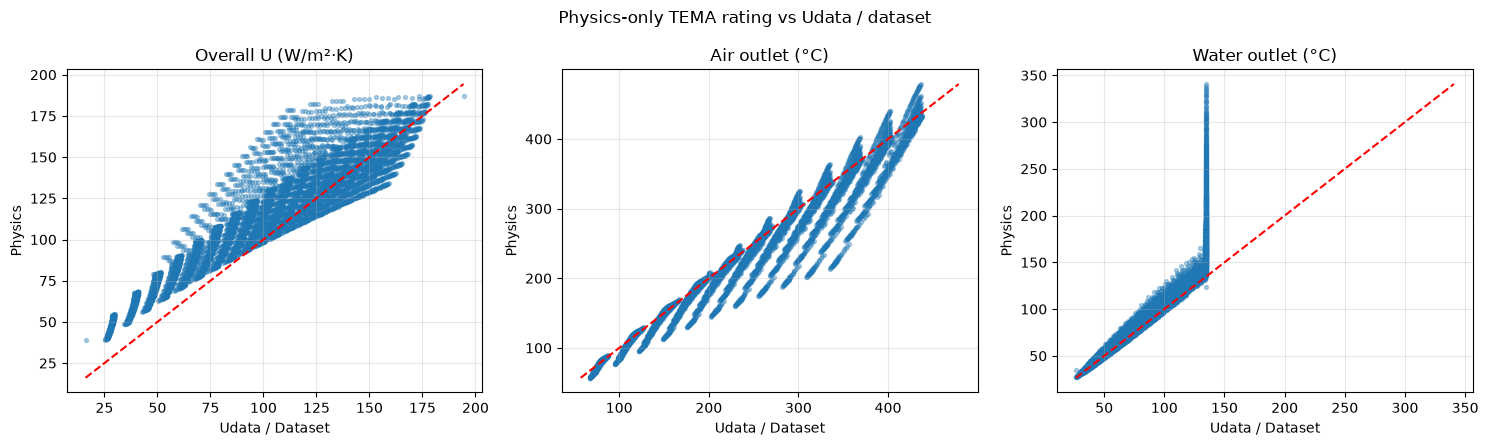

In [5]:
# PLOT ACTUAL DATA vs PHYSICS PREDICTIONS
# Goal:
#   Make 3 scatter plots for U, Taout, and Twout.
#   If points lie near the red dashed line, predictions are good.


# Create 1 row with 3 side-by-side plots
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Each item = (actual column, physics column, plot title)
pairs = [
    ("Udata", "U_physics", "Overall U (W/m²·K)"),
    ("T_air_out", "T_air_out_physics", "Air outlet (°C)"),
    ("T_water_out", "T_water_out_physics", "Water outlet (°C)"),
]

# Draw one scatter plot for each output variable
for ax, (a, p, title) in zip(axes, pairs):
    # Scatter: x = actual data , y = physics prediction
    ax.scatter(df[a], df[p], s=8, alpha=0.35)

    # Ideal line (y = x): perfect prediction would fall on this line
    lo = min(df[a].min(), df[p].min())
    hi = max(df[a].max(), df[p].max())
    ax.plot([lo, hi], [lo, hi], "r--", lw=1.5)

    ax.set_xlabel("Udata / Dataset")
    ax.set_ylabel("Physics")
    ax.set_title(title)
    ax.grid(True, alpha=0.3)

# Main title for all three plots
plt.suptitle("Physics-only TEMA rating vs Udata / dataset")
plt.tight_layout()
plt.show()


## 3. Digital Twin (physics only)

Enter the 4 inputs → get TEMA physics `U`, `Taout`, `Twout`.


In [6]:
def digital_twin_physics(m_air_kgh, m_water_kgh, T_air_in, T_water_in):
    """Physics-only digital twin. Mass flows in kg/h (same as data.csv)."""
    m_air = m_air_kgh / 3600.0
    m_water = m_water_kgh / 3600.0

    res = rate_shell_and_tube_1_2(
        T_air_in=T_air_in,
        m_dot_air=m_air,
        T_water_in=T_water_in,
        m_dot_water=m_water,
    )

    print("==========================================")
    print("   DIGITAL TWIN — PHYSICS ONLY")
    print("==========================================")
    print("\nINPUTS")
    print(f"  Air mass flow    : {m_air_kgh:.2f} kg/h  ({m_air:.4f} kg/s)")
    print(f"  Water mass flow  : {m_water_kgh:.2f} kg/h  ({m_water:.4f} kg/s)")
    print(f"  Air inlet temp   : {T_air_in:.2f} °C")
    print(f"  Water inlet temp : {T_water_in:.2f} °C")
    print("\nOUTPUTS")
    print(f"  Overall U        : {res['Overall_U (W/m²·K)']} W/m²·K")
    print(f"  Air outlet temp  : {res['Air_Outlet_Temp (°C)']} °C")
    print(f"  Water outlet temp: {res['Water_Outlet_Temp (°C)']} °C")
    print(f"  Duty             : {res['Calculated_Duty (kW)']} kW")
    print(f"  Iterations       : {res['Iterations_to_Converge']}")
    return res


# Example: Case 1 style inputs
_ = digital_twin_physics(
    m_air_kgh=10000,
    m_water_kgh=10000,
    T_air_in=100,
    T_water_in=25,
)


   DIGITAL TWIN — PHYSICS ONLY

INPUTS
  Air mass flow    : 10000.00 kg/h  (2.7778 kg/s)
  Water mass flow  : 10000.00 kg/h  (2.7778 kg/s)
  Air inlet temp   : 100.00 °C
  Water inlet temp : 25.00 °C

OUTPUTS
  Overall U        : 39.23 W/m²·K
  Air outlet temp  : 60.08 °C
  Water outlet temp: 34.65 °C
  Duty             : 111.88 kW
  Iterations       : 21


In [8]:
# --- USER INPUT: change values and re-run ---
user_m_air_kgh = 13701
user_m_water_kgh = 12901
user_T_air_in = 140
user_T_water_in = 38

twin = digital_twin_physics(
    user_m_air_kgh,
    user_m_water_kgh,
    user_T_air_in,
    user_T_water_in,
)

   DIGITAL TWIN — PHYSICS ONLY

INPUTS
  Air mass flow    : 13701.00 kg/h  (3.8058 kg/s)
  Water mass flow  : 12901.00 kg/h  (3.5836 kg/s)
  Air inlet temp   : 140.00 °C
  Water inlet temp : 38.00 °C

OUTPUTS
  Overall U        : 48.63 W/m²·K
  Air outlet temp  : 89.18 °C
  Water outlet temp: 51.08 °C
  Duty             : 195.48 kW
  Iterations       : 22
